# Fit group-specific curves with partial pooling

Groups may differ in their average response, in the shape of a relationship, or both. We will simulate groups with unequal sample sizes and compare models that allow different kinds of variation.

The small groups are particularly informative: they show how pooling changes a fitted curve when little data are available.

## Generate groups with unequal sample sizes

Each group has a shared sine trend, a constant shift, and a different curved deviation. We reserve test rows within every group, so the comparison concerns known groups.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from nampy.gam import GAM

rng = np.random.default_rng(101)
counts = {"A": 240, "B": 140, "C": 60, "D": 24}
shifts = {"A": -.45, "B": -.15, "C": .15, "D": .45}
slopes = {"A": -.6, "B": -.2, "C": .2, "D": .6}
def truth(x, group):
    return np.sin(2*np.pi*x) + shifts[group] + slopes[group]*np.cos(2*np.pi*x)
frames = []
for group, size in counts.items():
    x = rng.uniform(0, 1, size)
    frames.append(pd.DataFrame({"x": x, "group": group,
                               "y": truth(x, group) + rng.normal(0, .3, size)}))
data = pd.concat(frames, ignore_index=True)
data["group"] = pd.Categorical(data.group, categories=list(counts))
train, test = train_test_split(data, test_size=.25, stratify=data.group, random_state=101)
pd.DataFrame({"Group": list(counts), "Training rows": train.groupby("group", observed=False).size().to_numpy(),
              "Test rows": test.groupby("group", observed=False).size().to_numpy()}).style.hide(axis="index")

Group,Training rows,Test rows
A,180,60
B,105,35
C,45,15
D,18,6


## Fit a common curve with group intercepts

A parametric group coefficient shifts the common curve. A random intercept penalizes those shifts toward zero; it still cannot change the shape by group.

In [2]:
formulas = {
    "Group intercepts": "y ~ group + s(x, bs='cr', k=8)",
    "Random intercepts": "y ~ s(group, bs='re') + s(x, bs='cr', k=8)",
}
models = {}
for name, formula in formulas.items():
    models[name] = GAM(formula=formula, smoothing_method="reml", optimize_smoothing=True).fit(train)

## Fit separate factor-by smooths

Each level gets its own centered smooth. The parametric group term supplies the intercept differences that centering removes.

In [3]:
models["Separate smooths"] = GAM(formula="y ~ group + s(x, by=group, bs='cr', k=8)",
                                smoothing_method="reml", optimize_smoothing=True).fit(train)

## Share smoothing parameters across groups

Sharing a smoothing parameter gives the group curves a common penalty strength. It does not force their coefficients or shapes to match.

In [4]:
models["Shared smoothness"] = GAM(formula="y ~ group + s(x, by=group, bs='cr', k=8, id='shared')",
                                 smoothing_method="reml", optimize_smoothing=True).fit(train)

## Fit penalized group curves

The factor-smooth `fs` construction penalizes the entire group curve, including its null-space components. A separate group main effect would overlap those components, so it is omitted here.

In [5]:
models["Penalized curves"] = GAM(formula="y ~ s(group, x, bs='fs', k=8)",
                                smoothing_method="reml", optimize_smoothing=True).fit(train)

## Separate a global curve from group deviations

The `sz` construction constrains the group deviations to sum to zero. We include a global smooth and fixed group intercepts so average shifts and deviations have explicit roles.

In [6]:
models["Global plus deviations"] = GAM(formula="y ~ group + s(x, bs='cr', k=8) + s(group, x, bs='sz', k=8)",
                                      smoothing_method="reml", optimize_smoothing=True).fit(train)

## Compare predictions and fitted curves

Penalizing group effects and defining deviations around a global curve impose different structures. Compare their assumptions alongside their test errors.

| Specification | Intercept | Curve | Smoothness | Pooling / identifying assumption |
|---|---|---|---|---|
| Group intercepts | Fixed by group | Common | One curve penalty | Centered common smooth; no shrinkage of group shifts |
| Random intercepts | Penalized by group | Common | Curve and intercept penalties | Group shifts shrink toward zero |
| Separate smooths | Fixed by group | One per group | Separate by group | Each group smooth centered |
| Shared smoothness | Fixed by group | One per group | Shared across curves | Common penalty strength, not common coefficients |
| Penalized curves (`fs`) | Included in penalized curves | One per group | Shared penalty components | Entire curves penalized, including null spaces |
| Global plus deviations (`sz`) | Fixed by group | Global plus group deviations | Global/deviation penalties | Deviations sum to zero |


In [7]:
scores = pd.DataFrame([{"Model": name, "Test RMSE": mean_squared_error(test.y, model.predict(test))**.5}
                       for name, model in models.items()])
scores.style.hide(axis="index").format({"Test RMSE": "{:.3f}"})

Model,Test RMSE
Group intercepts,0.403
Random intercepts,0.404
Separate smooths,0.326
Shared smoothness,0.324
Penalized curves,0.324
Global plus deviations,0.326


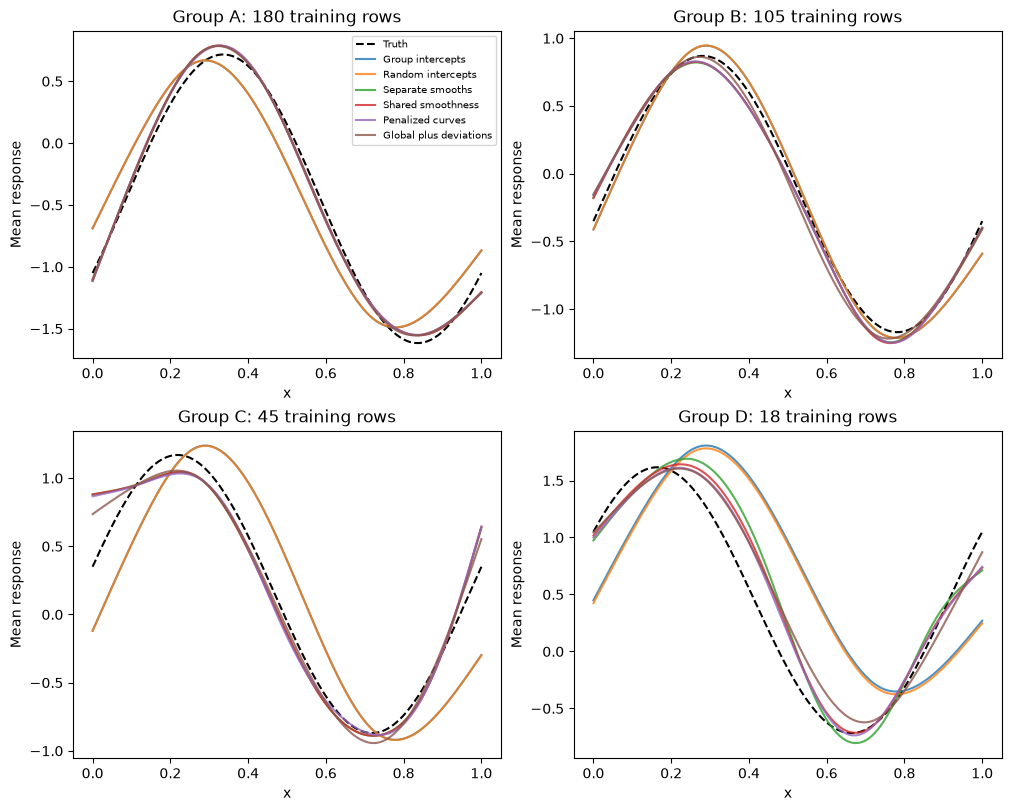

In [8]:
grid_x = np.linspace(0, 1, 160)
figure, axes = plt.subplots(2, 2, figsize=(10, 8), constrained_layout=True)
for axis, group in zip(axes.ravel(), counts):
    grid = pd.DataFrame({"x": grid_x, "group": pd.Categorical([group]*len(grid_x), categories=list(counts))})
    axis.plot(grid_x, truth(grid_x, group), "k--", label="Truth")
    for name, model in models.items():
        axis.plot(grid_x, model.predict(grid), label=name, alpha=.8)
    axis.set(title=f"Group {group}: {int((train.group == group).sum())} training rows", xlabel="x", ylabel="Mean response")
axes[0, 0].legend(fontsize=7)
plt.show()
plt.close(figure)

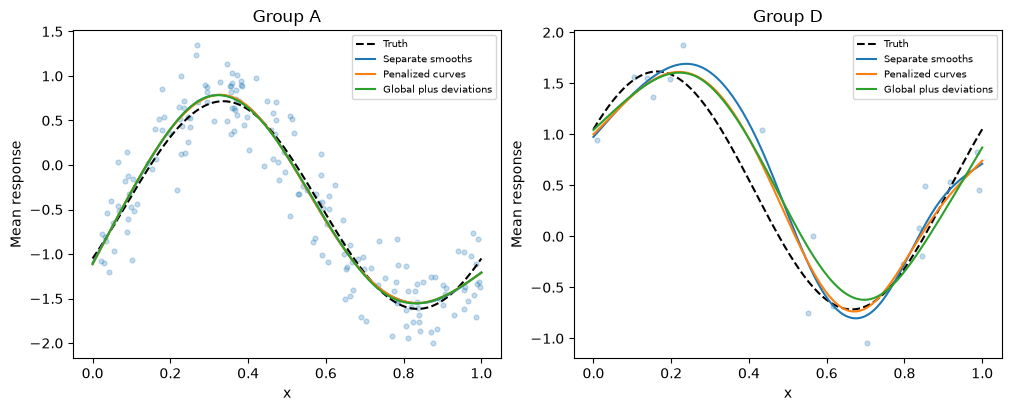

In [9]:
figure, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
for axis, group in zip(axes, ["A", "D"]):
    grid = pd.DataFrame({"x": grid_x, "group": pd.Categorical([group]*len(grid_x), categories=list(counts))})
    subset = train[train.group == group]
    axis.scatter(subset.x, subset.y, s=12, alpha=.25)
    axis.plot(grid_x, truth(grid_x, group), "k--", label="Truth")
    for name in ["Separate smooths", "Penalized curves", "Global plus deviations"]:
        axis.plot(grid_x, models[name].predict(grid), label=name)
    axis.set(title=f"Group {group}", xlabel="x", ylabel="Mean response")
    axis.legend(fontsize=7)
plt.show()
plt.close(figure)

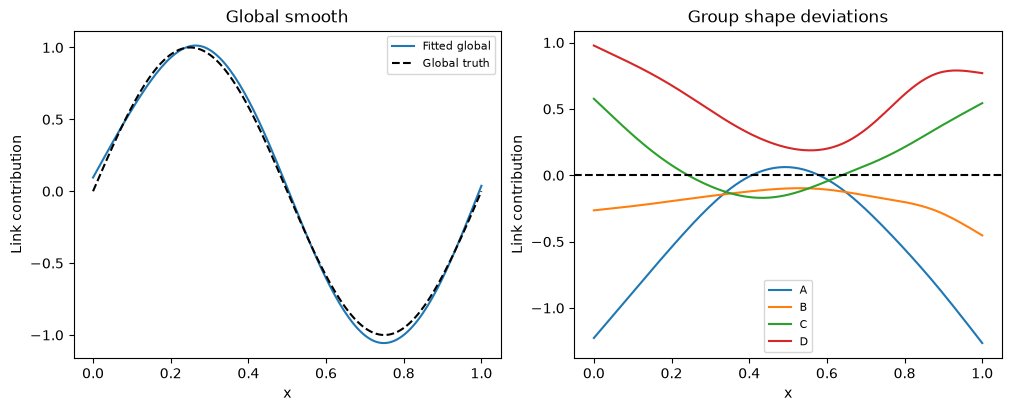

In [10]:
model = models["Global plus deviations"]
figure, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
for group in counts:
    grid = pd.DataFrame({"x": grid_x, "group": pd.Categorical([group]*len(grid_x), categories=list(counts))})
    matrix = model.lpmatrix(grid)
    result = model.fit_result()
    for term in result.term_results:
        start, stop = term.coef_slice
        contribution = matrix[:, start:stop] @ result.coef_full[start:stop]
        if term.label.startswith("s(x,") and group == "A":
            axes[0].plot(grid_x, contribution, label="Fitted global")
        if "bs='sz'" in term.label:
            axes[1].plot(grid_x, contribution, label=group)
axes[0].plot(grid_x, np.sin(2*np.pi*grid_x), "k--", label="Global truth")
axes[1].axhline(0, color="black", linestyle="--")
for axis, title in zip(axes, ["Global smooth", "Group shape deviations"]):
    axis.set(title=title, xlabel="x", ylabel="Link contribution")
    axis.legend(fontsize=8)
plt.show()
plt.close(figure)

The held-out scores describe prediction for these observed groups. They do not assess prediction for a new group. Curve estimates in small groups depend more strongly on the chosen penalty structure.

On this test split, the common-curve models have RMSE about 0.40, whereas the group-curve constructions are around 0.32–0.33. Sharing smoothing or penalizing full curves gives similar prediction errors here; the small-group panels help assess their different curve estimates. Pooled test RMSE weights every observation equally, so the larger groups dominate it. The smallest group contributes very few test observations, making its apparent performance particularly uncertain.